# Modelo 1 - Regresión: predicción de la nota final (G3)

# 1.Importación librerías

In [1]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import Dense, Dropout

from tensorflow.keras.callbacks import EarlyStopping


# 2.Importación fuente de datos

In [2]:
#Lectura de los datos ya limpios y procesados en 02_Preprocesamiento
train = pd.read_csv('../data/processed/train.csv')
test = pd.read_csv('../data/processed/test.csv')

In [3]:
train.shape, test.shape

((835, 64), (209, 64))

In [4]:
train.head()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes,materia_matematicas,materia_portugues,G3,nivel_riesgo
0,16,3,3,1,2,0,4,3,2,1,...,0,1,1,0,1,0,0,1,13,2
1,15,3,2,1,2,0,4,2,2,1,...,0,1,0,1,1,0,1,0,19,1
2,16,4,3,1,2,0,5,4,2,1,...,0,1,0,1,1,0,0,1,13,2
3,16,2,3,1,2,0,2,3,1,1,...,0,1,0,1,1,0,0,1,14,1
4,17,1,1,3,1,1,5,2,1,1,...,0,1,0,1,0,1,1,0,0,4


# 3.Preparación de variables

## 3.1 Versión A: con notas parciales (G1 y G2)

In [5]:
#Variable objetivo: G3 (nota final). Es la misma para las dos versiones
y_train = train['G3']
y_test = test['G3']

In [6]:
#Versión A: todas las variables de entrada (quitamos G3, que es la salida, y nivel_riesgo, que se calculó a partir de G3)
X_train_A = train.drop(['G3','nivel_riesgo'],axis=1)
X_test_A = test.drop(['G3','nivel_riesgo'],axis=1)
X_train_A.shape, X_test_A.shape

((835, 62), (209, 62))

## 3.2 Versión B: sin notas parciales (sin G1, G2 ni promedio_notas)

In [7]:
#Versión B: sin notas parciales, para una alerta temprana (antes de tener notas del año)
#Además de G3 y nivel_riesgo, quitamos G1, G2 y promedio_notas (que se calcula con G1 y G2)
columnas_notas = ['G3','nivel_riesgo','G1','G2','promedio_notas']
X_train_B = train.drop(columnas_notas,axis=1)
X_test_B = test.drop(columnas_notas,axis=1)
X_train_B.shape, X_test_B.shape

((835, 59), (209, 59))

# 4.Escalado

In [8]:
from sklearn.preprocessing import MinMaxScaler

In [9]:
#Scaler de la Versión A (62 columnas). Se ajusta SOLO con los datos de entrenamiento
scaler_A = MinMaxScaler()
scaler_A.fit(X_train_A)
X_train_A = scaler_A.transform(X_train_A)
X_test_A = scaler_A.transform(X_test_A)

In [10]:
#Scaler de la Versión B (59 columnas, sin G1, G2 ni promedio_notas)
scaler_B = MinMaxScaler()
scaler_B.fit(X_train_B)
X_train_B = scaler_B.transform(X_train_B)
X_test_B = scaler_B.transform(X_test_B)

In [11]:
X_train_A.max(), X_train_A.min(), X_train_B.max(), X_train_B.min()

(np.float64(1.0), np.float64(0.0), np.float64(1.0), np.float64(0.0))

# 5.Creación del modelo

In [12]:
def crear_modelo(num_entradas, usar_dropout):
    model = Sequential()
    #Capa oculta 1: tantas neuronas como variables de entrada (como recomienda el profe)
    model.add(Dense(num_entradas, activation='relu'))
    if usar_dropout:
        model.add(Dropout(0.2)) #apaga el 20% de las neuronas en cada paso para evitar overfitting
    #Capa oculta 2: la mitad de neuronas
    model.add(Dense(num_entradas // 2, activation='relu'))
    if usar_dropout:
        model.add(Dropout(0.2))
    #Capa de salida: 1 neurona SIN función de activación, porque es regresión (predice un número: G3)
    model.add(Dense(1))
    model.compile(optimizer='adam', loss='mse') #mse: error cuadrático medio, la función de coste de regresión
    return model

In [13]:
modelo_prueba = crear_modelo(X_train_A.shape[1], True)
modelo_prueba.build(input_shape=(None, X_train_A.shape[1]))
modelo_prueba.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 62)             │         3,906 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 62)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 31)             │         1,953 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 31)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            32 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,891 (23.01 KB)

 Trainable params: 5,891 (23.01 KB)

 Non-trainable params: 0 (0.00 B)

## 6.1 Versión A sin Dropout

In [14]:
import tensorflow as tf
tf.keras.utils.set_random_seed(101) #fija el azar para que el entrenamiento dé el mismo resultado cada vez que se corre

#EarlyStopping: detiene el entrenamiento si val_loss no mejora en 25 epochs seguidos
early_stop = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=25, restore_best_weights=True)

In [15]:
modelo_A = crear_modelo(X_train_A.shape[1], False)

modelo_A.fit(x=X_train_A, y=y_train.values,

             validation_split=0.2, #el 20% del entrenamiento se usa para validar en cada epoch (el test NO se toca hasta el final)

             batch_size=32, epochs=500,

             callbacks=[early_stop], verbose=0)


Epoch 64: early stopping
Restoring model weights from the end of the best epoch: 39.


<Axes: >

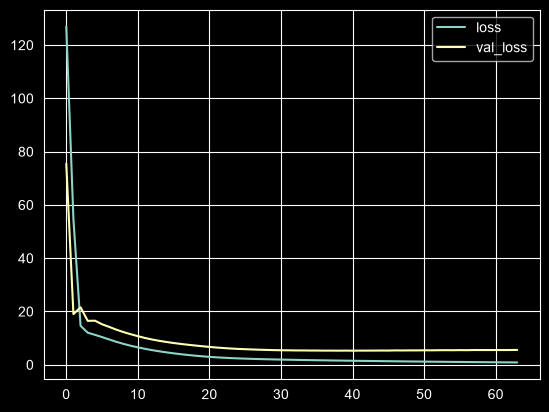

In [16]:
perdidas_A = pd.DataFrame(modelo_A.history.history) #pérdidas de entrenamiento (loss) y validación (val_loss)
perdidas_A.plot()

## 6.2 Versión A con Dropout

In [17]:
tf.keras.utils.set_random_seed(101)
modelo_A_drop = crear_modelo(X_train_A.shape[1], True)

modelo_A_drop.fit(x=X_train_A, y=y_train.values,
                  validation_split=0.2,
                  batch_size=32, epochs=500,
                  callbacks=[early_stop], verbose=0)

Epoch 100: early stopping
Restoring model weights from the end of the best epoch: 75.


<Axes: >

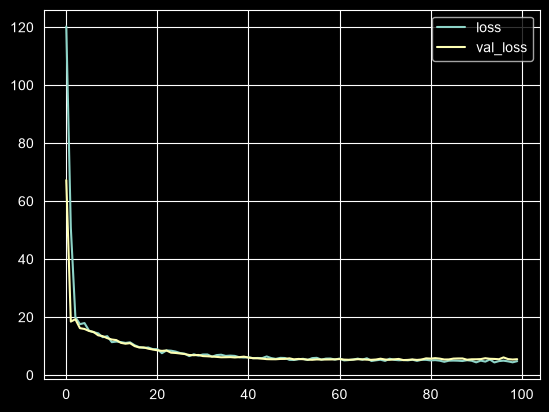

In [18]:
perdidas_A_drop = pd.DataFrame(modelo_A_drop.history.history)
perdidas_A_drop.plot()

## 6.3 Versión B sin Dropout

In [19]:
tf.keras.utils.set_random_seed(101)
modelo_B = crear_modelo(X_train_B.shape[1], False)

modelo_B.fit(x=X_train_B, y=y_train.values,
             validation_split=0.2,
             batch_size=32, epochs=500,
             callbacks=[early_stop], verbose=0);

Epoch 57: early stopping
Restoring model weights from the end of the best epoch: 32.


<Axes: >

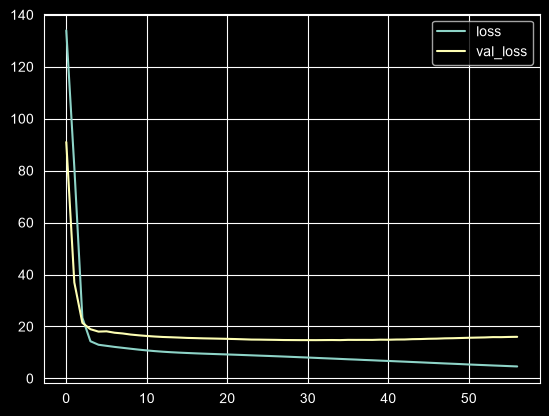

In [20]:
perdidas_B = pd.DataFrame(modelo_B.history.history)
perdidas_B.plot()

## 6.4 Versión B con Dropout

In [21]:
tf.keras.utils.set_random_seed(101)
modelo_B_drop = crear_modelo(X_train_B.shape[1], True)

modelo_B_drop.fit(x=X_train_B, y=y_train.values,
                  validation_split=0.2,
                  batch_size=32, epochs=500,
                  callbacks=[early_stop], verbose=0);

Epoch 53: early stopping
Restoring model weights from the end of the best epoch: 28.


<Axes: >

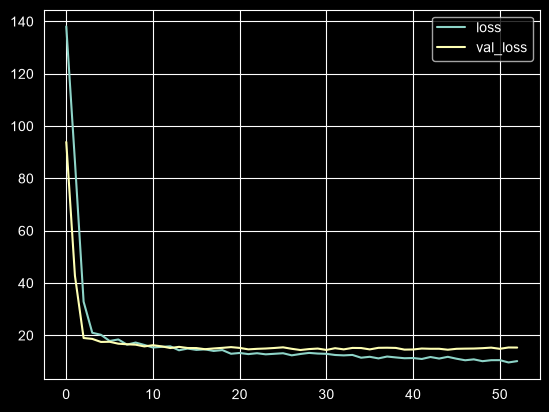

In [22]:
perdidas_B_drop = pd.DataFrame(modelo_B_drop.history.history)
perdidas_B_drop.plot()

# 7.Evaluación del modelo

# 8.Comparación y selección del mejor modelo

# 9.Guardar el modelo